# 🎗️ Cancer Prediction using Machine Learning

This notebook builds a breast cancer classification model from the provided `cancer.csv` dataset.

**Workflow:** Load data → clean missing values → explore data → preprocess numeric/categorical features → train multiple supervised ML models → evaluate → select the best model by F1-score → save the trained model.

> **Important:** This is an educational machine-learning project and is **not a medical diagnosis tool**.

## 1. Import Libraries

In [1]:
import os
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

In [2]:
# Find cancer.csv in common project locations.
candidate_paths = [
    Path("../data/cancer.csv"),
    Path("data/cancer.csv"),
    Path("cancer.csv"),
    Path("../../data/cancer.csv")
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "cancer.csv was not found. Put it inside the project's data folder."
    )

df = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully from: ..\data\cancer.csv
Shape: (213, 11)


,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
0,1,2019,40,1,2,0,Right,0,Upper inner,0,Benign
1,2,2019,39,1,2,0,Left,0,Upper outer,0,Benign
2,3,2019,45,0,4,0,Left,0,Lower outer,0,Benign
3,4,2019,26,1,3,0,Left,0,Lower inner,1,Benign
4,5,2019,21,1,1,0,Right,0,Upper outer,1,Benign


## 3. Understand the Dataset

In [3]:
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 213 entries, 0 to 212
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   S/N               213 non-null    int64
 1   Year              213 non-null    str  
 2   Age               213 non-null    int64
 3   Menopause         213 non-null    int64
 4   Tumor Size (cm)   213 non-null    str  
 5   Inv-Nodes         213 non-null    str  
 6   Breast            213 non-null    str  
 7   Metastasis        213 non-null    str  
 8   Breast Quadrant   213 non-null    str  
 9   History           213 non-null    str  
 10  Diagnosis Result  213 non-null    str  
dtypes: int64(3), str(8)
memory usage: 24.8 KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
S/N,213.0,NaN,NaN,NaN,107.0,61.631972,1.0,54.0,107.0,160.0,213.0
Year,213,3,2020,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,213.0,NaN,NaN,NaN,39.784038,14.096712,13.0,30.0,40.0,49.0,77.0
Menopause,213.0,NaN,NaN,NaN,0.666667,0.472515,0.0,0.0,1.0,1.0,1.0
Tumor Size (cm),213,13,3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inv-Nodes,213,4,0,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Breast,213,3,Left,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metastasis,213,3,0,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Breast Quadrant,213,6,Upper outer,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
History,213,3,0,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Rows: 213
Columns: 11


## 4. Clean Column Names and Missing Values

In [4]:
# Remove leading/trailing spaces from column names.
df.columns = df.columns.str.strip()

# Remove the serial-number column because it is only an identifier.
id_columns = [c for c in ["S/N", "id", "ID", "Id"] if c in df.columns]
if id_columns:
    df = df.drop(columns=id_columns)

# In this dataset, '#' represents a missing/unknown value.
df = df.replace("#", np.nan)

# Remove accidental spaces from text values.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Columns after cleaning:")
print(df.columns.tolist())

print("\nMissing values after converting '#' to NaN:")
display(df.isna().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Columns after cleaning:
['Year', 'Age', 'Menopause', 'Tumor Size (cm)', 'Inv-Nodes', 'Breast', 'Metastasis', 'Breast Quadrant', 'History', 'Diagnosis Result']

Missing values after converting '#' to NaN:


,Missing Values
Year,1
Age,0
Menopause,0
Tumor Size (cm),1
Inv-Nodes,1
Breast,6
Metastasis,1
Breast Quadrant,2
History,2
Diagnosis Result,0



Duplicate rows: 0


In [5]:
# Remove exact duplicate rows.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows.")
print("New shape:", df.shape)

target_column = "Diagnosis Result"

if target_column not in df.columns:
    raise KeyError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

print("\nTarget distribution:")
display(df[target_column].value_counts(dropna=False))

Removed 0 duplicate rows.
New shape: (213, 10)

Target distribution:


Diagnosis Result
Benign       120
Malignant     93
Name: count, dtype: int64

## 5. Target Distribution

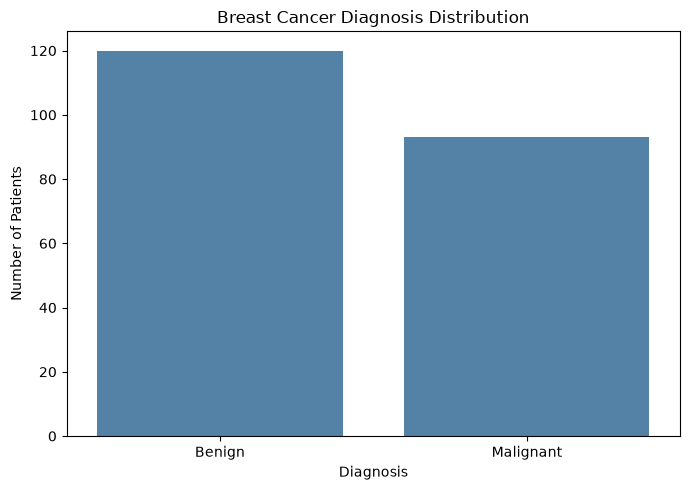

Target percentage:


Diagnosis Result
Benign       56.34
Malignant    43.66
Name: proportion, dtype: float64

In [6]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target_column, color="steelblue")
plt.title("Breast Cancer Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

print("Target percentage:")
display((df[target_column].value_counts(normalize=True) * 100).round(2))

## 6. Exploratory Data Analysis

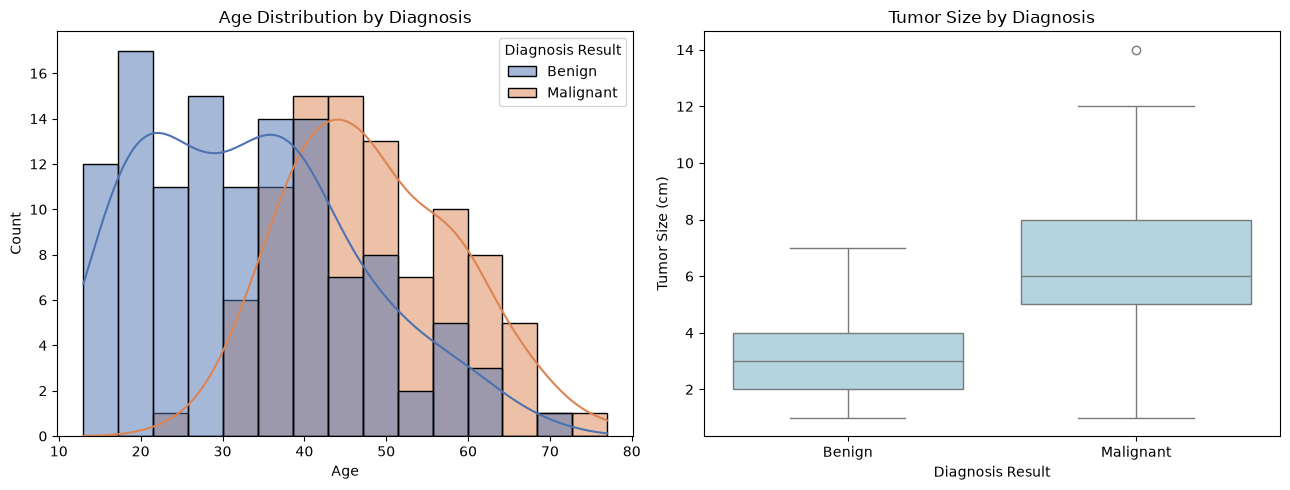

In [7]:
# Convert selected numeric-looking columns for EDA only.
eda_df = df.copy()

numeric_candidates = ["Year", "Age", "Menopause", "Tumor Size (cm)", "Inv-Nodes", "Metastasis", "History"]
for col in numeric_candidates:
    if col in eda_df.columns:
        eda_df[col] = pd.to_numeric(eda_df[col], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=eda_df, x="Age", hue=target_column, kde=True, bins=15, ax=axes[0], palette="deep")
axes[0].set_title("Age Distribution by Diagnosis")

sns.boxplot(data=eda_df, x=target_column, y="Tumor Size (cm)", ax=axes[1], color="lightblue")
axes[1].set_title("Tumor Size by Diagnosis")

plt.tight_layout()
plt.show()

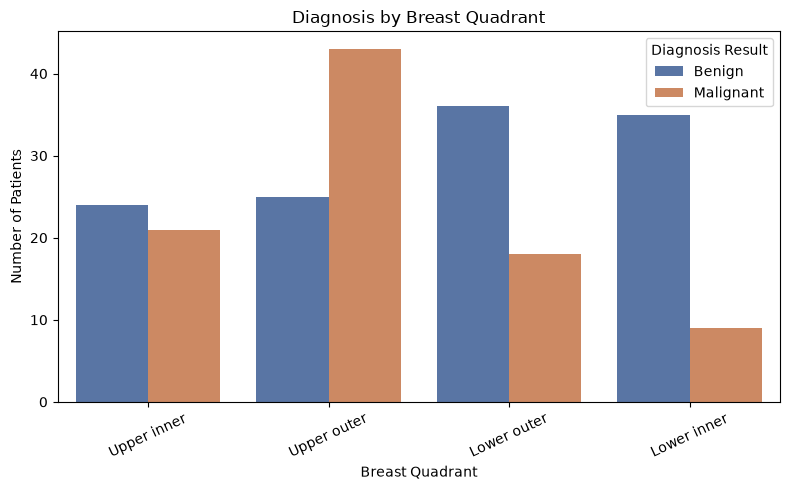

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Breast Quadrant", hue=target_column, palette="deep")
plt.title("Diagnosis by Breast Quadrant")
plt.xlabel("Breast Quadrant")
plt.ylabel("Number of Patients")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 7. Prepare Features and Target

In [9]:
X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

# Convert the target to binary labels:
# Benign = 0, Malignant = 1
target_map = {"Benign": 0, "Malignant": 1}
y = y.map(target_map)

if y.isna().any():
    raise ValueError("Unexpected values found in the diagnosis column.")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget encoding:")
print("Benign = 0")
print("Malignant = 1")
print(y.value_counts())

Feature shape: (213, 9)
Target shape: (213,)

Target encoding:
Benign = 0
Malignant = 1
Diagnosis Result
0    120
1     93
Name: count, dtype: int64


## 8. Train-Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (170, 9)
Testing data: (43, 9)


## 9. Preprocessing Pipeline

In [11]:
# Identify numeric and categorical columns automatically.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Numeric features: ['Age', 'Menopause']
Categorical features: ['Year', 'Tumor Size (cm)', 'Inv-Nodes', 'Breast', 'Metastasis', 'Breast Quadrant', 'History']
Preprocessing pipeline created successfully.


## 10. Define and Train Multiple Models

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name} trained successfully.")

print("\nAll models trained.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
KNN trained successfully.

All models trained.


## 11. Evaluate Models

In [13]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.8837,0.8889,0.8421,0.8649,0.9561
1,KNN,0.8837,0.9375,0.7895,0.8571,0.8904
2,Decision Tree,0.8605,0.8421,0.8421,0.8421,0.9002
3,Random Forest,0.8605,0.8824,0.7895,0.8333,0.9583


## 12. Model Comparison

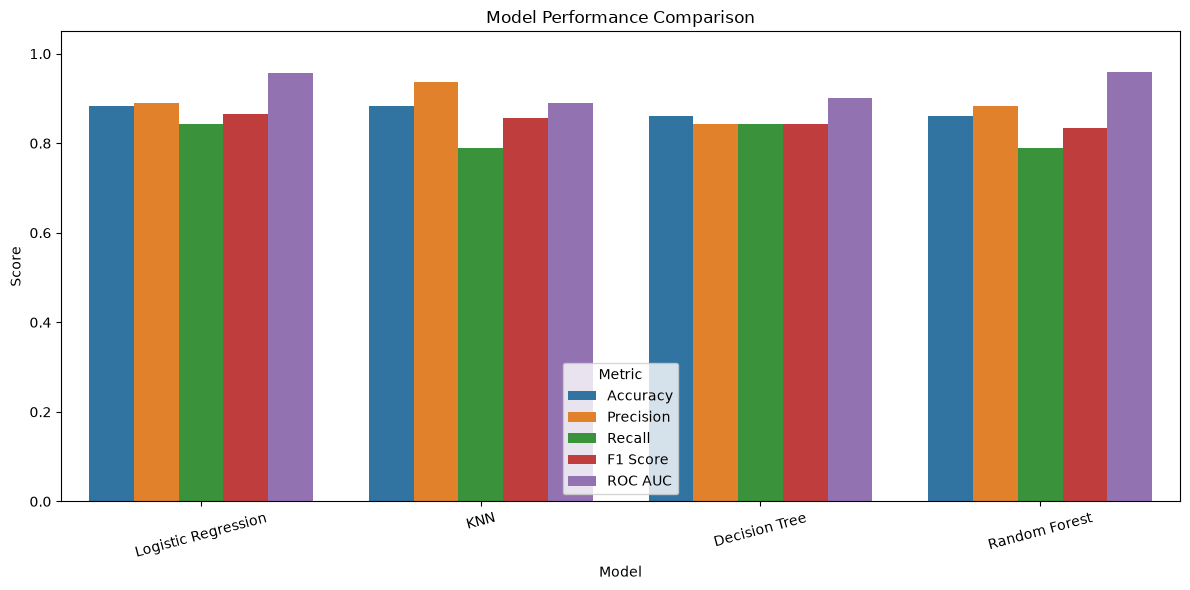

In [14]:
results_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 13. Select the Model with the Highest F1 Score

In [15]:
best_model_name = results_df.loc[results_df["F1 Score"].idxmax(), "Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("Reason: it has the highest F1 Score among the tested models.")

Selected model: Logistic Regression
Reason: it has the highest F1 Score among the tested models.


## 14. Confusion Matrix

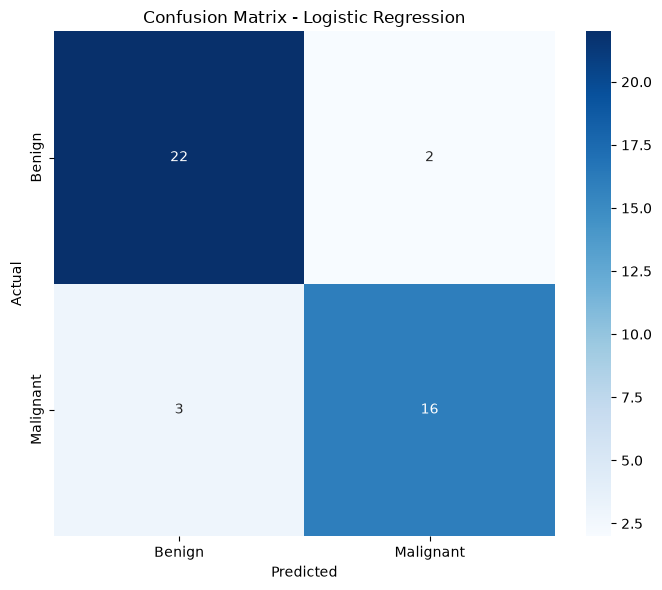

Confusion matrix:
[[22  2]
 [ 3 16]]


In [16]:
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

## 15. Classification Report

In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

              precision    recall  f1-score   support

      Benign       0.88      0.92      0.90        24
   Malignant       0.89      0.84      0.86        19

    accuracy                           0.88        43
   macro avg       0.88      0.88      0.88        43
weighted avg       0.88      0.88      0.88        43



## 16. ROC Curve

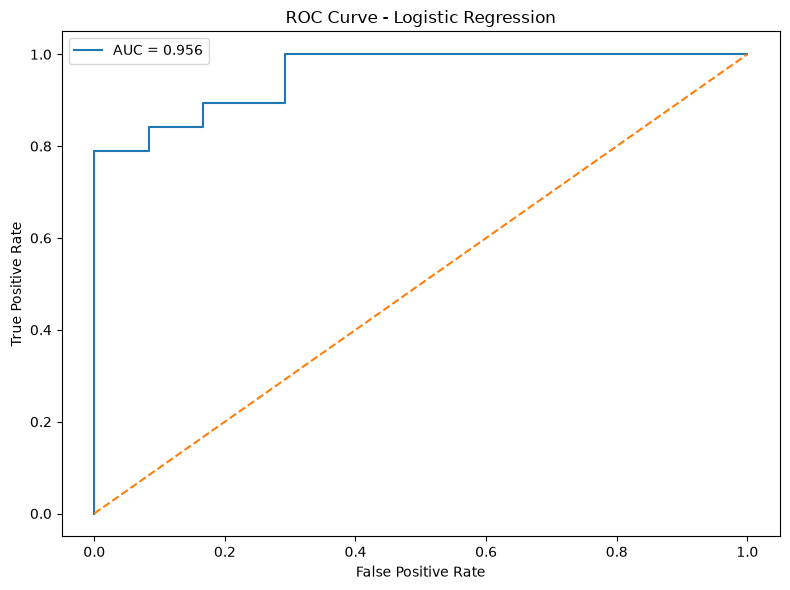

In [18]:
y_probability = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_probability)
auc_score = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Feature Importance / Model Information

In [19]:
# Feature importance is shown when the selected estimator supports it.
estimator = best_model.named_steps["model"]

if hasattr(estimator, "feature_importances_"):
    feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    importance = pd.Series(
        estimator.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(10, 7))
    sns.barplot(x=importance.values, y=importance.index, color="steelblue")
    plt.title(f"Top 15 Feature Importances - {best_model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_model_name} does not provide tree-style feature_importances_.")
    print("The model was trained successfully and can still be used for prediction.")

Logistic Regression does not provide tree-style feature_importances_.
The model was trained successfully and can still be used for prediction.


## 18. Save the Trained Model

In [20]:
# Save the complete pipeline, not just the estimator.
# This ensures the same cleaning, encoding and scaling are used in Streamlit.
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "features": list(X.columns),
    "target_mapping": {"Benign": 0, "Malignant": 1}
}

model_dir_candidates = [
    Path("../models"),
    Path("models"),
    Path("../../models")
]

model_dir = next((p for p in model_dir_candidates if p.exists()), None)

if model_dir is None:
    model_dir = Path("models")
    model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "cancer_model.pkl"
joblib.dump(model_package, model_path)

print("Model saved successfully:")
print(model_path.resolve())

Model saved successfully:
C:\Users\VANSHIKA\OneDrive\Desktop\cancer_prediction\models\cancer_model.pkl


## 19. Test a Single Prediction

In [21]:
# Test the saved pipeline with one real test-row.
sample = X_test.iloc[[0]].copy()

sample_prediction = best_model.predict(sample)[0]
sample_probability = best_model.predict_proba(sample)[0, 1]

prediction_label = "Malignant" if sample_prediction == 1 else "Benign"

print("Prediction:", prediction_label)
print(f"Malignant probability: {sample_probability:.2%}")

Prediction: Malignant
Malignant probability: 95.09%


## 20. Project Complete

The complete preprocessing + model pipeline has been saved as:

`models/cancer_model.pkl`

The Streamlit app should load this single pipeline and pass the same feature columns in the same order. Because the preprocessing is inside the saved pipeline, the app does not need a separate scaler or manual one-hot encoding.

**Note:** This project is for educational purposes only and should not be used to diagnose or treat a patient.